In [ ]:
# Analyze only this saved inversion and timestamp index (zero-based).
run_path = './outputs/gneiss_rgb_095000_103000_step60s.h5'
time_index = 1

# Inversion NaN analysis
Set the inversion HDF5 path and zero-based timestamp index in the **first cell**. Only that timestamp is analyzed; no other runs are searched or selected. Files are opened read-only. This notebook only reads saved products; it never runs an inversion.

Missing means nonfinite (NaN or infinity). Fixed ownership distinguishes geometric gaps from failed inversions. Files without `owner_site` are rejected.

In [28]:
from pathlib import Path
import json
from datetime import datetime
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display

project_root = Path.cwd()
if not (project_root / 'config.toml').exists() and (project_root.parent / 'config.toml').exists():
    project_root = project_root.parent
if not run_path:
    raise ValueError('Set run_path in the first cell to an inversion HDF5 file.')
run_path = Path(run_path).expanduser()
if not run_path.is_absolute():
    run_path = project_root / run_path
if not run_path.is_file():
    raise FileNotFoundError(run_path)
print('Analyzing:', run_path)


Analyzing: /Users/anniepflaum/lab317/asispectralinversion/outputs/gneiss_rgb_095000_103000_step60s.h5


In [29]:
with h5py.File(run_path, 'r') as f:
    required = ('owner_site', 'completed', 'time_iso', 'gridlat', 'gridlon',
                'combined/q_mW_m2', 'combined/e0_eV')
    absent = [key for key in required if key not in f]
    if absent:
        raise ValueError(f'Missing required datasets: {absent}')
    attrs = dict(f.attrs)
    owner = f['owner_site'][:]
    completed = f['completed'][:].astype(bool)
    times = pd.to_datetime([datetime.fromisoformat(t) for t in f['time_iso'].asstr()[:]], utc=True)
    lat, lon = f['gridlat'][:], f['gridlon'][:]
    fields = [key for key in ('q_mW_m2', 'e0_eV', 'sigp_S', 'sigh_S') if key in f['combined']]
    for key in fields:
        if f['combined'][key].shape != (len(times), *owner.shape):
            raise ValueError(f'Unexpected shape for {key}')
    if completed.shape != (len(times),) or lat.shape != owner.shape or lon.shape != owner.shape:
        raise ValueError('Inconsistent time or coordinate dimensions')
site_codes = json.loads(attrs.get('site_codes_json', '{}'))
site_names = {int(code): name for name, code in site_codes.items()}
owned = owner > 0
n_owned = int(owned.sum())
if not n_owned:
    raise ValueError('This run has no owned pixels')
display(pd.Series({
    'timestamps': len(times), 'completed': int(completed.sum()),
    'unfinished': int((~completed).sum()), 'owned pixels': n_owned,
    'outside coverage pixels': int((~owned).sum()),
    'ownership method': attrs.get('ownership_method', 'unspecified'),
    'pixel selection': attrs.get('inversion_pixel_selection', 'unspecified'),
}))
display(pd.Series(attrs, name='saved provenance'))
if isinstance(time_index, bool) or not isinstance(time_index, (int, np.integer)):
    raise ValueError('Set time_index to an integer in the first cell.')
selected_index = int(time_index)
if not 0 <= selected_index < len(times):
    raise IndexError(f'time_index must be between 0 and {len(times)-1}')
if not completed[selected_index]:
    raise ValueError('Selected timestamp is unfinished; its fill values cannot diagnose inversion failures.')
print('Selected inversion:', selected_index, times[selected_index])


timestamps                                                              41
completed                                                               41
unfinished                                                               0
owned pixels                                                         77238
outside coverage pixels                                             141498
ownership method           fixed_geometric_owner_no_fallback_either_finite
pixel selection                                           fixed_owner_only
dtype: object

apex_reference_time                                           20260210T10:24:00
blue_dark_frame_subtracted                                                False
blue_timing_json              {"ARV": [{"path": "/Users/anniepflaum/lab317/d...
calibration_json              {"ARV": {"red": 40.0, "green": 64.0, "blue": 3...
common_mapping_altitude_km                                                110.0
date                                                                   20260210
end                                                                    10:30:00
format                                           gneiss_multisite_rgb_inversion
glow_params_json              {"ARV": [26041.0, 37440.0, 68.12699890136719, ...
inversion_pixel_selection                                      fixed_owner_only
ownership_method                fixed_geometric_owner_no_fallback_either_finite
schema_version                                                              1.3
site_codes_json                         

Selected inversion: 0 2026-02-10 09:50:00+00:00


## Selected inversion summary
Percentages use each site's fixed owned area at the selected timestamp. Missing Q/E0 does not prove both solvers failed: current merging retains each available component; older outputs may mask both when either failed.

In [30]:
rows, site_rows = [], []
missing_counts = {key: np.zeros(owner.shape, dtype=np.int64) for key in fields}
pair_missing_count = np.zeros(owner.shape, dtype=np.int64)
with h5py.File(run_path, 'r') as f:
    for index in [selected_index]:
        data = {key: f['combined'][key][index] for key in fields}
        pair_ok = np.isfinite(data['q_mW_m2']) & np.isfinite(data['e0_eV'])
        pair_bad = owned & ~pair_ok
        pair_missing_count += pair_bad
        row = {'index': int(index), 'time': times[index],
               'qe_missing_pct': 100 * pair_bad.sum() / n_owned}
        for key, values in data.items():
            missing = owned & ~np.isfinite(values)
            missing_counts[key] += missing
            row[f'{key}_missing_pct'] = 100 * missing.sum() / n_owned
            row[f'{key}_nan_pixels'] = int((owned & np.isnan(values)).sum())
            row[f'{key}_inf_pixels'] = int((owned & np.isinf(values)).sum())
            if key in ('sigp_S', 'sigh_S'):
                row[f'{key}_missing_with_valid_qe'] = int((missing & pair_ok).sum())
        if 'source_site' in f['combined']:
            source = f['combined/source_site'][index]
            source_ok = pair_ok if attrs.get('ownership_method') != 'fixed_geometric_owner_no_fallback_either_finite' else (np.isfinite(data['q_mW_m2']) | np.isfinite(data['e0_eV']))
            row['source_inconsistency_pixels'] = int(((source_ok & ((source != owner) | ~owned)) |
                                                     (~source_ok & (source != 0))).sum())
        rows.append(row)
        for site_code in np.unique(owner[owned]):
            mask = owner == site_code
            site_rows.append({'index': int(index), 'time': times[index],
                              'site': site_names.get(int(site_code), str(site_code)),
                              'owned_pixels': int(mask.sum()),
                              'qe_missing_pixels': int((mask & ~pair_ok).sum()),
                              'qe_missing_pct': 100 * (mask & ~pair_ok).sum() / mask.sum()})
summary = pd.DataFrame(rows)
by_site = pd.DataFrame(site_rows)
if summary.empty:
    raise ValueError('No completed timestamps: saved NaNs are uncomputed, not inversion failures.')
display(summary)
display(by_site)


,index,time,qe_missing_pct,q_mW_m2_missing_pct,q_mW_m2_nan_pixels,q_mW_m2_inf_pixels,e0_eV_missing_pct,e0_eV_nan_pixels,e0_eV_inf_pixels,sigp_S_missing_pct,sigp_S_nan_pixels,sigp_S_inf_pixels,sigp_S_missing_with_valid_qe,sigh_S_missing_pct,sigh_S_nan_pixels,sigh_S_inf_pixels,sigh_S_missing_with_valid_qe,source_inconsistency_pixels
0,0,2026-02-10 09:50:00+00:00,0.772936,0.502343,388,0,0.772936,597,0,0.772936,597,0,0,0.772936,597,0,0,0


,index,time,site,owned_pixels,qe_missing_pixels,qe_missing_pct
0,0,2026-02-10 09:50:00+00:00,ARV,35095,308,0.877618
1,0,2026-02-10 09:50:00+00:00,VEE,13428,288,2.144772
2,0,2026-02-10 09:50:00+00:00,BVR,28715,1,0.003483


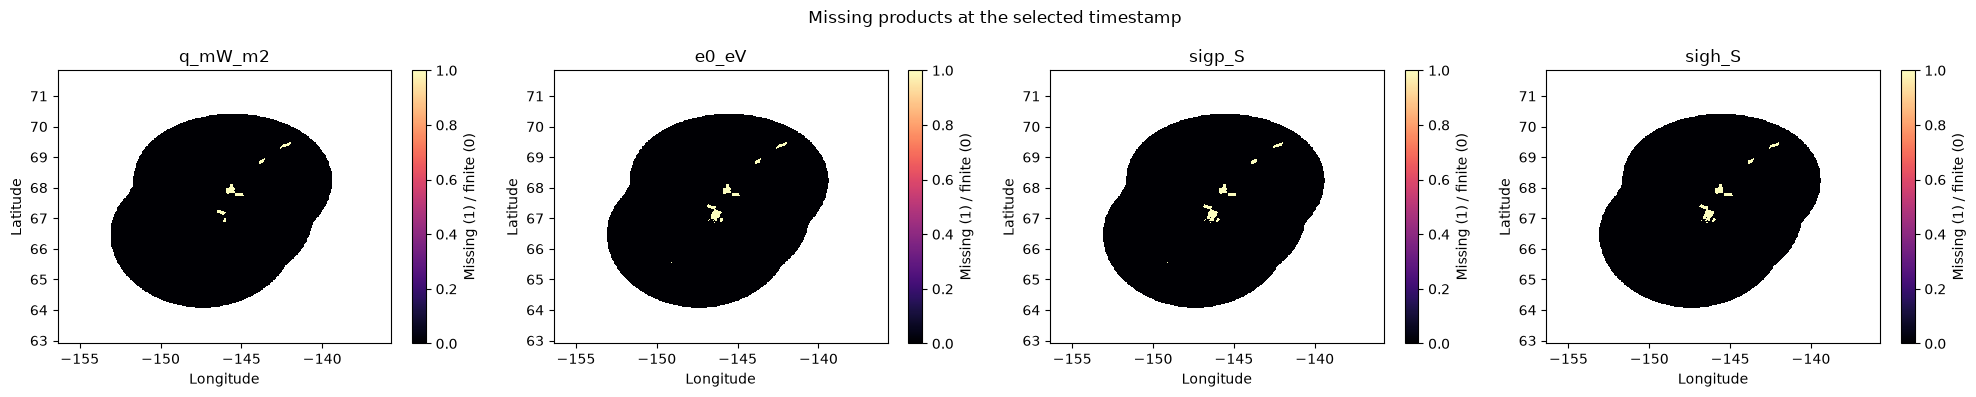

In [31]:
fig, axes = plt.subplots(1, len(fields), figsize=(5 * len(fields), 4), squeeze=False)
for ax, key in zip(axes.flat, fields):
    fraction = np.where(owned, missing_counts[key].astype(float), np.nan)
    plot = ax.pcolormesh(lon, lat, fraction, shading='auto', vmin=0, vmax=1, cmap='magma')
    ax.set(title=key, xlabel='Longitude', ylabel='Latitude')
    fig.colorbar(plot, ax=ax, label='Missing (1) / finite (0)')
fig.suptitle('Missing products at the selected timestamp')
plt.tight_layout(); plt.show()

## Selected timestamp: evidence-supported categories
The category map prioritizes outside coverage, then unfinished frames, then missing Q/E0, then conductance-only failures. Conductance categories apply only to datasets present in the file. Gray pixels are expected geometric gaps, not failed inversions.

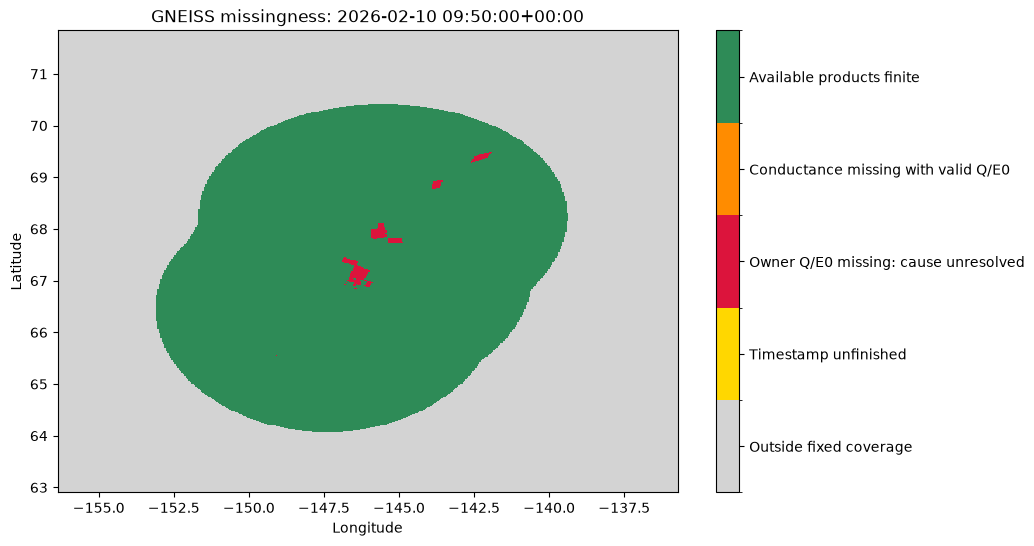

,category,pixels
0,Outside fixed coverage,141498
1,Timestamp unfinished,0
2,Owner Q/E0 missing: cause unresolved,597
3,Conductance missing with valid Q/E0,0
4,Available products finite,76641


In [32]:
with h5py.File(run_path, 'r') as f:
    selected = {key: f['combined'][key][selected_index] for key in fields}
category = np.zeros(owner.shape, dtype=np.uint8)
if not completed[selected_index]:
    category[owned] = 1
else:
    qe_ok = np.isfinite(selected['q_mW_m2']) & np.isfinite(selected['e0_eV'])
    category[owned & ~qe_ok] = 2
    category[owned & qe_ok] = 4
    conductance_bad = np.zeros(owner.shape, dtype=bool)
    for key in ('sigp_S', 'sigh_S'):
        if key in selected:
            conductance_bad |= ~np.isfinite(selected[key])
    category[owned & qe_ok & conductance_bad] = 3
labels = ['Outside fixed coverage', 'Timestamp unfinished', 'Owner Q/E0 missing: cause unresolved',
          'Conductance missing with valid Q/E0', 'Available products finite']
colors = ListedColormap(['lightgray', 'gold', 'crimson', 'darkorange', 'seagreen'])
fig, ax = plt.subplots(figsize=(10, 6))
plot = ax.pcolormesh(lon, lat, category, shading='auto', cmap=colors,
                     norm=BoundaryNorm(np.arange(-.5, 5), colors.N))
bar = fig.colorbar(plot, ax=ax, ticks=range(5)); bar.ax.set_yticklabels(labels)
ax.set(title=f'GNEISS missingness: {times[selected_index]}', xlabel='Longitude', ylabel='Latitude')
plt.show()
display(pd.DataFrame({'category': labels, 'pixels': [(category == i).sum() for i in range(5)]}))

## NaN reasons from saved data
New files contain `combined/failure_reason`: the recorded first failed stage, including input validity, Q lookup bounds, E0 crossings, or conductance failure. Older files instead show which quantities are missing; those categories cannot establish the exact solver cause. The plot and per-site counts below always run without replay.

,site,reason,pixels
0,ARV,Q/E0 and requested conductances finite,34787
1,ARV,Q lookup failed within brightness range,308
2,VEE,Q/E0 and requested conductances finite,13140
3,VEE,Nonpositive RGB input,80
4,VEE,Red/green ratio has no crossing at Q,208
5,BVR,Q/E0 and requested conductances finite,28714
6,BVR,Red/green ratio has no crossing at Q,1


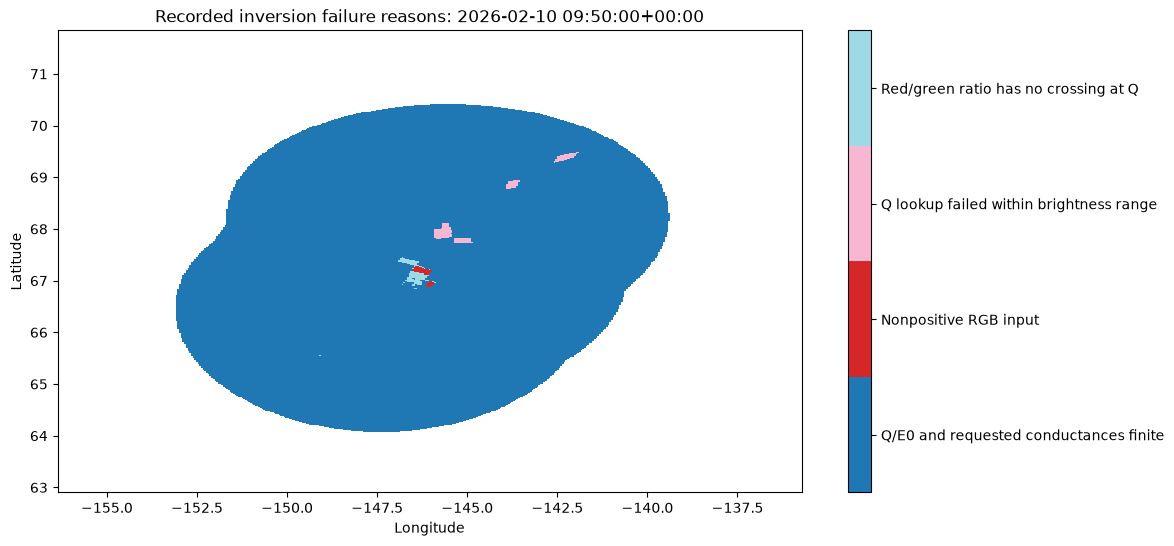

In [33]:
# Recorded during the original inversion: no replay needed.
with h5py.File(run_path, 'r') as f:
    if 'combined/failure_reason' not in f:
        recorded_reasons = None
        print('No failure_reason dataset in this file. Showing saved-output categories; exact solver causes are unavailable.')
    else:
        dataset = f['combined/failure_reason']
        recorded_reasons = dataset[selected_index]
        labels = {int(k): v for k, v in json.loads(dataset.attrs['codes_json']).items()}
if recorded_reasons is None:
    q_ok = np.isfinite(selected['q_mW_m2'])
    e_ok = np.isfinite(selected['e0_eV'])
    recorded_reasons = np.zeros(owner.shape, dtype=np.uint8)
    recorded_reasons[owned & ~q_ok & ~e_ok] = 1
    recorded_reasons[owned & q_ok & ~e_ok] = 2
    recorded_reasons[owned & ~q_ok & e_ok] = 3
    conductance_missing = np.zeros(owner.shape, dtype=bool)
    for field in ('sigp_S', 'sigh_S'):
        if field in selected:
            conductance_missing |= ~np.isfinite(selected[field])
    recorded_reasons[owned & q_ok & e_ok & conductance_missing] = 4
    labels = {0: 'Available products finite',
              1: 'Q and E0 missing — exact cause not recorded',
              2: 'E0 missing, Q finite — exact cause not recorded',
              3: 'Q missing, E0 finite — exact cause not recorded',
              4: 'Conductance missing with finite Q/E0 — cause not recorded'}
    reason_plot_title = 'Saved-output categories (exact reasons unavailable)'
else:
    reason_plot_title = 'Recorded inversion failure reasons'
if recorded_reasons is not None:
    rows = []
    for code in np.unique(owner[owned]):
        for reason in np.unique(recorded_reasons[owner == code]):
            rows.append({'site': site_names.get(int(code), str(code)),
                         'reason': labels.get(int(reason), f'Unknown code {reason}'),
                         'pixels': int(((owner == code) & (recorded_reasons == reason)).sum())})
    display(pd.DataFrame(rows))
    present = np.unique(recorded_reasons[owned])
    mapped = np.full(owner.shape, np.nan)
    for i, reason in enumerate(present):
        mapped[owned & (recorded_reasons == reason)] = i
    fig, ax = plt.subplots(figsize=(12, 6))
    plot = ax.pcolormesh(lon, lat, mapped, shading='auto',
                        cmap=plt.get_cmap('tab20', len(present)), vmin=-.5, vmax=len(present)-.5)
    bar = fig.colorbar(plot, ax=ax, ticks=range(len(present)))
    bar.ax.set_yticklabels([labels.get(int(r), str(r)) for r in present])
    ax.set(title=f'{reason_plot_title}: {times[selected_index]}', xlabel='Longitude', ylabel='Latitude')
    plt.show()
